# Khám phá dữ liệu `cell_features.parquet`

Notebook này mô tả dữ liệu không gian đã tạo cho khu vực `29_3`.

```text
Đọc dữ liệu → xem cấu trúc → kiểm tra chất lượng
→ phân tích POI → khoảng cách nearest → mạng đường
→ tương quan → bản đồ phân bố không gian
```

Notebook chỉ đọc GeoParquet, không chạy lại pipeline OSM hoặc Overture.

In [35]:
from pathlib import Path
import re

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise FileNotFoundError("Không tìm thấy project root")


ROOT = find_root()
DATA_PATH = ROOT / "data/processed/29_3/cell_features.parquet"
features = gpd.read_parquet(DATA_PATH)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

print("File:", DATA_PATH)
print(f"Kích thước: {features.shape[0]:,} cell × {features.shape[1]} cột")
print("CRS:", features.crs)

File: d:\FPT\SEMESTER\FALL26\ADY201m\Group Assignment\ADY201_FA26\data\processed\29_3\cell_features.parquet
Kích thước: 85,249 cell × 135 cột
CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 48N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "a

## 1. Tổng quan dữ liệu

Mỗi hàng là một grid cell 200 m. Các cột mô tả geometry, số POI, số POI theo bán kính, khoảng cách tới POI gần nhất và đặc điểm mạng đường.

In [36]:
radius_pattern = re.compile(r"_count_(100|200|500|1000|2000|5000)m$")
groups = {
    "Thông tin cell": ["cell_id", "cell_area_km2", "geometry", "points"],
    "POI trực tiếp": [
        c for c in features.columns
        if c == "poi_count" or (c.endswith("_count") and c != "poi_count")
    ],
    "POI theo bán kính": [c for c in features.columns if radius_pattern.search(c)],
    "Khoảng cách nearest": [c for c in features.columns if c.startswith("nearest_")],
    "Mạng đường": [c for c in features.columns if c.startswith("road_")],
}

group_summary = pd.DataFrame(
    {
        "nhóm cột": groups.keys(),
        "số cột": [len(columns) for columns in groups.values()],
        "ví dụ": [", ".join(columns[:3]) for columns in groups.values()],
    }
)
display(group_summary)
display(features[["cell_id", "cell_area_km2", "poi_count"]].head())

,nhóm cột,số cột,ví dụ
0,Thông tin cell,4,"cell_id, cell_area_km2, geometry"
1,POI trực tiếp,14,"poi_count, arts_and_entertainment_count, commu..."
2,POI theo bán kính,78,"arts_and_entertainment_count_100m, arts_and_en..."
3,Khoảng cách nearest,35,"nearest_arts_and_entertainment_m, nearest_comm..."
4,Mạng đường,4,"road_length_500m_km, road_density_500m_km_per_..."


,cell_id,cell_area_km2,poi_count
0,cell_000000,0.00,0
1,cell_000001,0.02,0
2,cell_000002,0.04,0
3,cell_000003,0.02,0
4,cell_000004,0.04,0


## 2. Kiểm tra chất lượng dữ liệu

In [37]:
numeric = features.select_dtypes(include="number")
quality = pd.Series(
    {
        "Cell trùng cell_id": features["cell_id"].duplicated().sum(),
        "Cell thiếu cell_id": features["cell_id"].isna().sum(),
        "Geometry bị thiếu": features.geometry.isna().sum(),
        "Geometry không hợp lệ": (~features.geometry.is_valid).sum(),
        "Giá trị numeric bị thiếu": numeric.isna().sum().sum(),
        "Giá trị numeric vô hạn": np.isinf(numeric).sum().sum(),
        "Giá trị numeric âm": (numeric < 0).sum().sum(),
    },
    name="số lượng",
)
display(quality.to_frame())

missing = features.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0].head(15)
if len(missing):
    ax = missing.sort_values().plot.barh(
        figsize=(9, 5), color="#E15759", title="Các cột thiếu dữ liệu nhiều nhất"
    )
    ax.set_xlabel("Missing (%)")
    plt.tight_layout()
    plt.show()
else:
    print("✓ Không có giá trị thiếu trong dataset.")

,số lượng
Cell trùng cell_id,0
Cell thiếu cell_id,0
Geometry bị thiếu,0
Geometry không hợp lệ,0
Giá trị numeric bị thiếu,0
Giá trị numeric vô hạn,0
Giá trị numeric âm,0


✓ Không có giá trị thiếu trong dataset.


## 3. POI trong phạm vi đi bộ gần

Các cột dưới đây đếm POI trong bán kính 200 m quanh cell. Tỷ lệ bằng 0 cho biết mức độ thưa của từng nhóm tiện ích.

,mean,median,q90,max,zero_%
Đồ ăn,2.04,0.00,1.00,569,83.72
Dịch vụ,2.70,0.00,3.00,460,68.05
Mua sắm,3.51,0.00,3.00,614,76.53
Giáo dục,0.61,0.00,1.00,99,87.25
Y tế,0.37,0.00,0.00,73,90.46
Giao thông,0.39,0.00,0.00,147,91.06


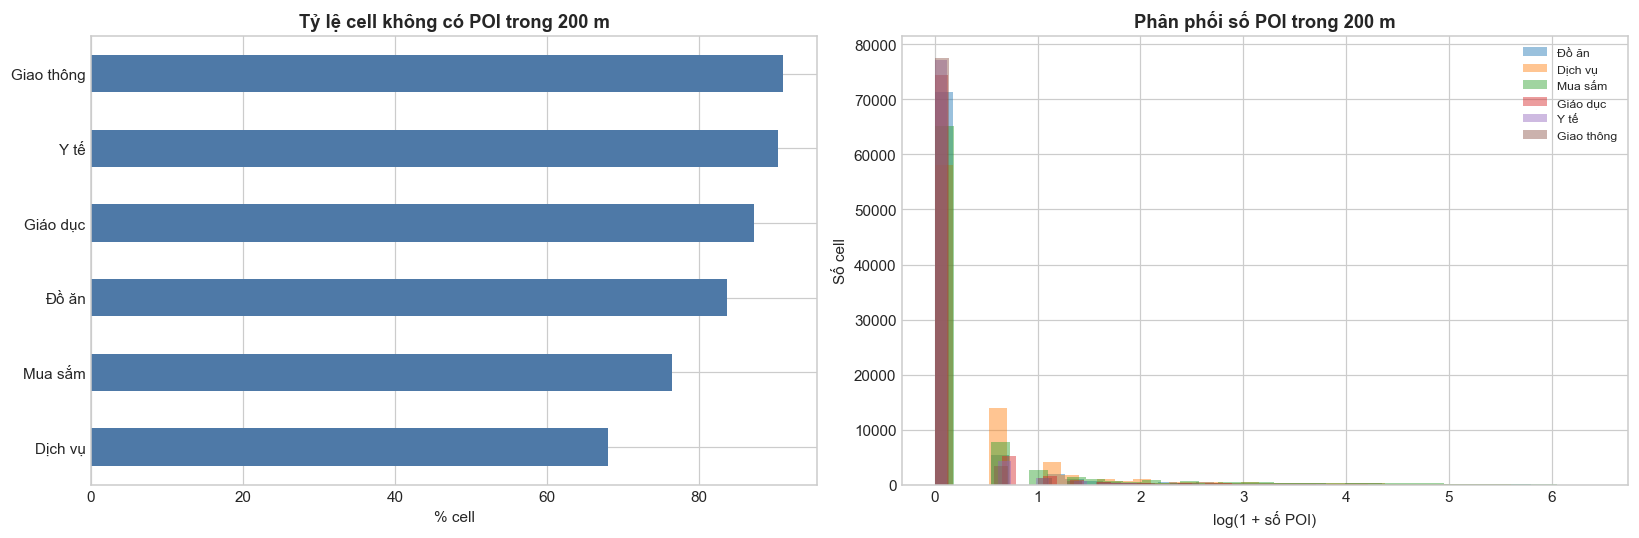

In [38]:
poi_200m = {
    "Đồ ăn": "food_and_drink_count_200m",
    "Dịch vụ": "services_and_business_count_200m",
    "Mua sắm": "shopping_count_200m",
    "Giáo dục": "education_count_200m",
    "Y tế": "health_care_count_200m",
    "Giao thông": "travel_and_transportation_count_200m",
}

poi_summary = pd.DataFrame(
    {
        "mean": {name: features[column].mean() for name, column in poi_200m.items()},
        "median": {name: features[column].median() for name, column in poi_200m.items()},
        "q90": {name: features[column].quantile(0.90) for name, column in poi_200m.items()},
        "max": {name: features[column].max() for name, column in poi_200m.items()},
        "zero_%": {name: 100 * (features[column] == 0).mean() for name, column in poi_200m.items()},
    }
)
display(poi_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
poi_summary["zero_%"].sort_values().plot.barh(ax=axes[0], color="#4E79A7")
axes[0].set(title="Tỷ lệ cell không có POI trong 200 m", xlabel="% cell")

for name, column in poi_200m.items():
    axes[1].hist(
        np.log1p(features[column]), bins=35, alpha=0.45, label=name
    )
axes[1].set(
    title="Phân phối số POI trong 200 m",
    xlabel="log(1 + số POI)",
    ylabel="Số cell",
)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Số POI tăng như thế nào khi mở rộng bán kính?

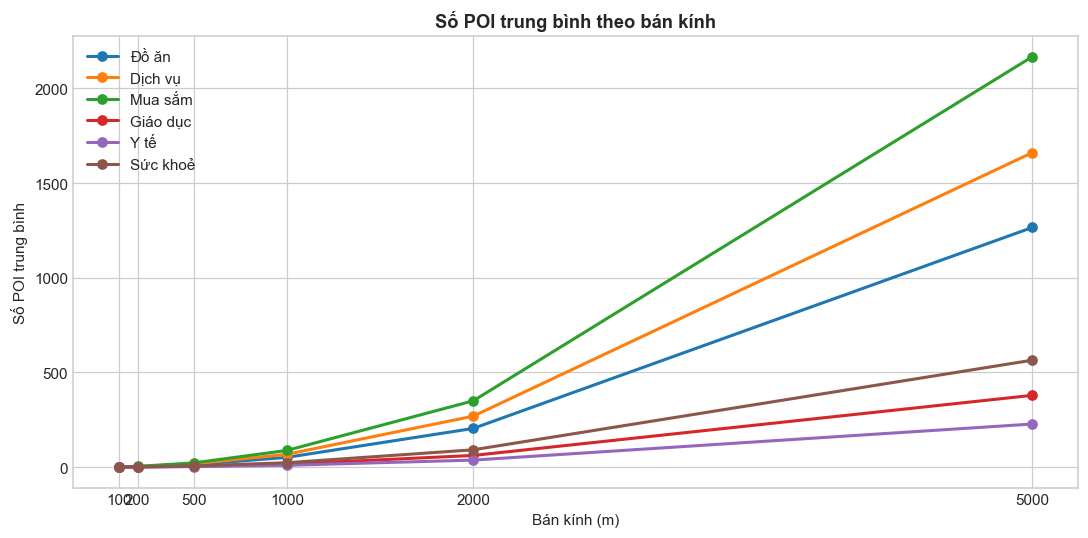

In [50]:
radii = [100, 200, 500, 1000, 2000, 5000]
radius_groups = {
    "Đồ ăn": "food_and_drink",
    "Dịch vụ": "services_and_business",
    "Mua sắm": "shopping",
    "Giáo dục": "education",
    "Y tế": "health_care",
    "Sức khoẻ": "lifestyle_services"
}

mean_by_radius = pd.DataFrame(
    {
        label: [features[f"{prefix}_count_{radius}m"].mean() for radius in radii]
        for label, prefix in radius_groups.items()
    },
    index=radii,
)

ax = mean_by_radius.plot(marker="o", figsize=(10, 5), linewidth=2)
ax.set_xticks(radii, [str(radius) for radius in radii])
ax.set(title="Số POI trung bình theo bán kính", xlabel="Bán kính (m)", ylabel="Số POI trung bình")
plt.tight_layout()
plt.show()

## 4. Khoảng cách tới tiện ích gần nhất

Khoảng cách được đổi sang kilomet để dễ đọc. Boxplot không hiển thị outlier nhằm tập trung vào phần lớn cell.

,mean,25%,50%,75%,90%,max
Bệnh viện,2.48,1.04,1.93,3.27,5.39,11.74
Trường học,1.67,0.79,1.45,2.30,3.21,8.38
Thực phẩm,1.78,0.72,1.38,2.36,3.77,11.02
Công viên,4.32,1.72,3.48,6.37,8.95,18.08
Trạm xe buýt,10.12,4.92,9.08,14.31,19.11,33.71
Nhà thuốc,1.91,0.87,1.58,2.56,3.79,9.74


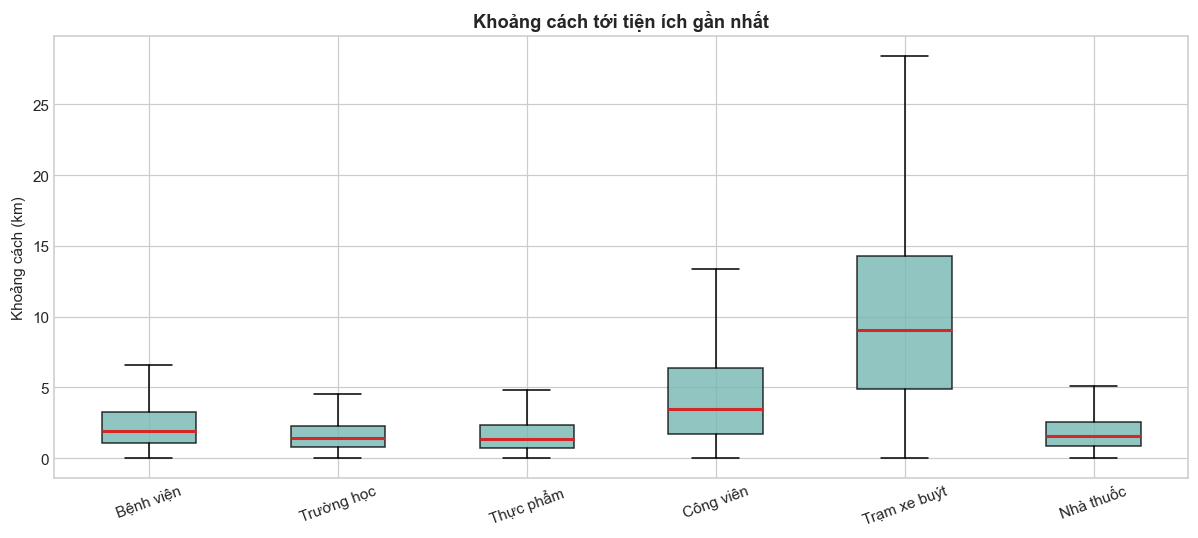

In [40]:
nearest = {
    "Bệnh viện": "nearest_hospital_m",
    "Trường học": "nearest_school_m",
    "Thực phẩm": "nearest_grocery_store_m",
    "Công viên": "nearest_park_m",
    "Trạm xe buýt": "nearest_bus_station_m",
    "Nhà thuốc": "nearest_pharmacy_m",
}

nearest_km = pd.DataFrame(
    {name: features[column] / 1000 for name, column in nearest.items()}
)
nearest_summary = nearest_km.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T
display(nearest_summary[["mean", "25%", "50%", "75%", "90%", "max"]].round(2))

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot(
    [nearest_km[column] for column in nearest_km],
    tick_labels=nearest_km.columns,
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#76B7B2", "alpha": 0.8},
    medianprops={"color": "#D62728", "linewidth": 2},
)
ax.set(title="Khoảng cách tới tiện ích gần nhất", ylabel="Khoảng cách (km)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 5. Mạng đường quanh cell

,mean,std,25%,50%,75%,max
500 m,9.70,7.04,5.49,8.46,11.76,56.18
1.000 m,9.73,6.38,6.27,8.55,11.09,49.50


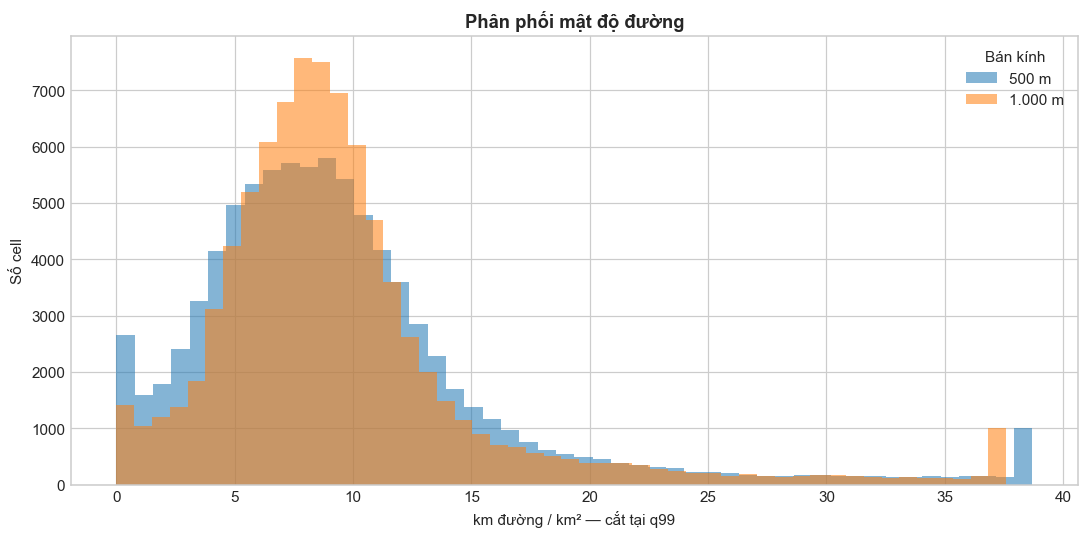

In [41]:
road_columns = {
    "500 m": "road_density_500m_km_per_km2",
    "1.000 m": "road_density_1000m_km_per_km2",
}

road_summary = features[list(road_columns.values())].describe().T
road_summary.index = road_columns.keys()
display(road_summary[["mean", "std", "25%", "50%", "75%", "max"]].round(2))

fig, ax = plt.subplots(figsize=(10, 5))
for label, column in road_columns.items():
    cap = features[column].quantile(0.99)
    ax.hist(features[column].clip(upper=cap), bins=50, alpha=0.55, label=label)
ax.set(
    title="Phân phối mật độ đường",
    xlabel="km đường / km² — cắt tại q99",
    ylabel="Số cell",
)
ax.legend(title="Bán kính")
plt.tight_layout()
plt.show()

## 6. Tương quan giữa các feature chính

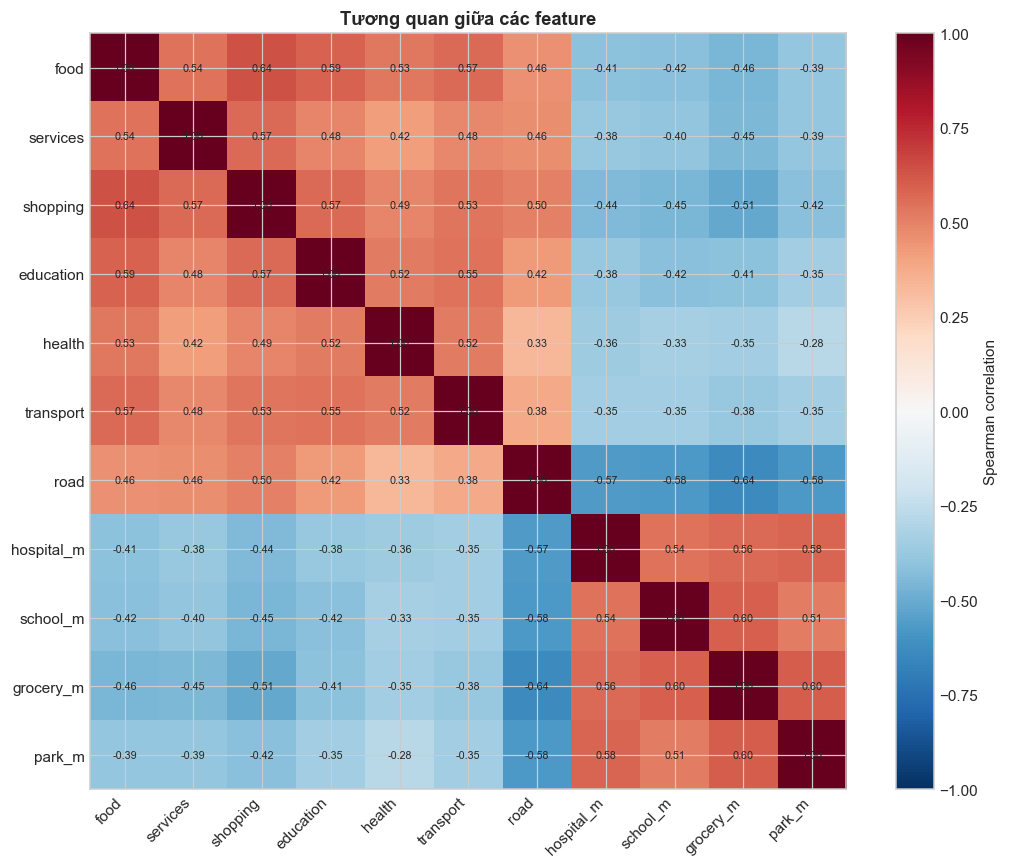

In [42]:
correlation_columns = [
    *poi_200m.values(),
    "road_density_1000m_km_per_km2",
    "nearest_hospital_m",
    "nearest_school_m",
    "nearest_grocery_store_m",
    "nearest_park_m",
]
corr = features[correlation_columns].corr(method="spearman")
short_labels = [
    "food", "services", "shopping", "education", "health", "transport",
    "road", "hospital_m", "school_m", "grocery_m", "park_m",
]

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(short_labels)), short_labels, rotation=45, ha="right")
ax.set_yticks(range(len(short_labels)), short_labels)
for row in range(len(corr)):
    for column in range(len(corr)):
        ax.text(column, row, f"{corr.iloc[row, column]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="Spearman correlation")
ax.set_title("Tương quan giữa các feature")
plt.tight_layout()
plt.show()

## 7. Phân bố không gian ở trung tâm Hà Nội

Để bản đồ dễ đọc, các giá trị rất lớn được giới hạn tại percentile 99. Việc này chỉ ảnh hưởng cách tô màu, không thay đổi dữ liệu gốc.

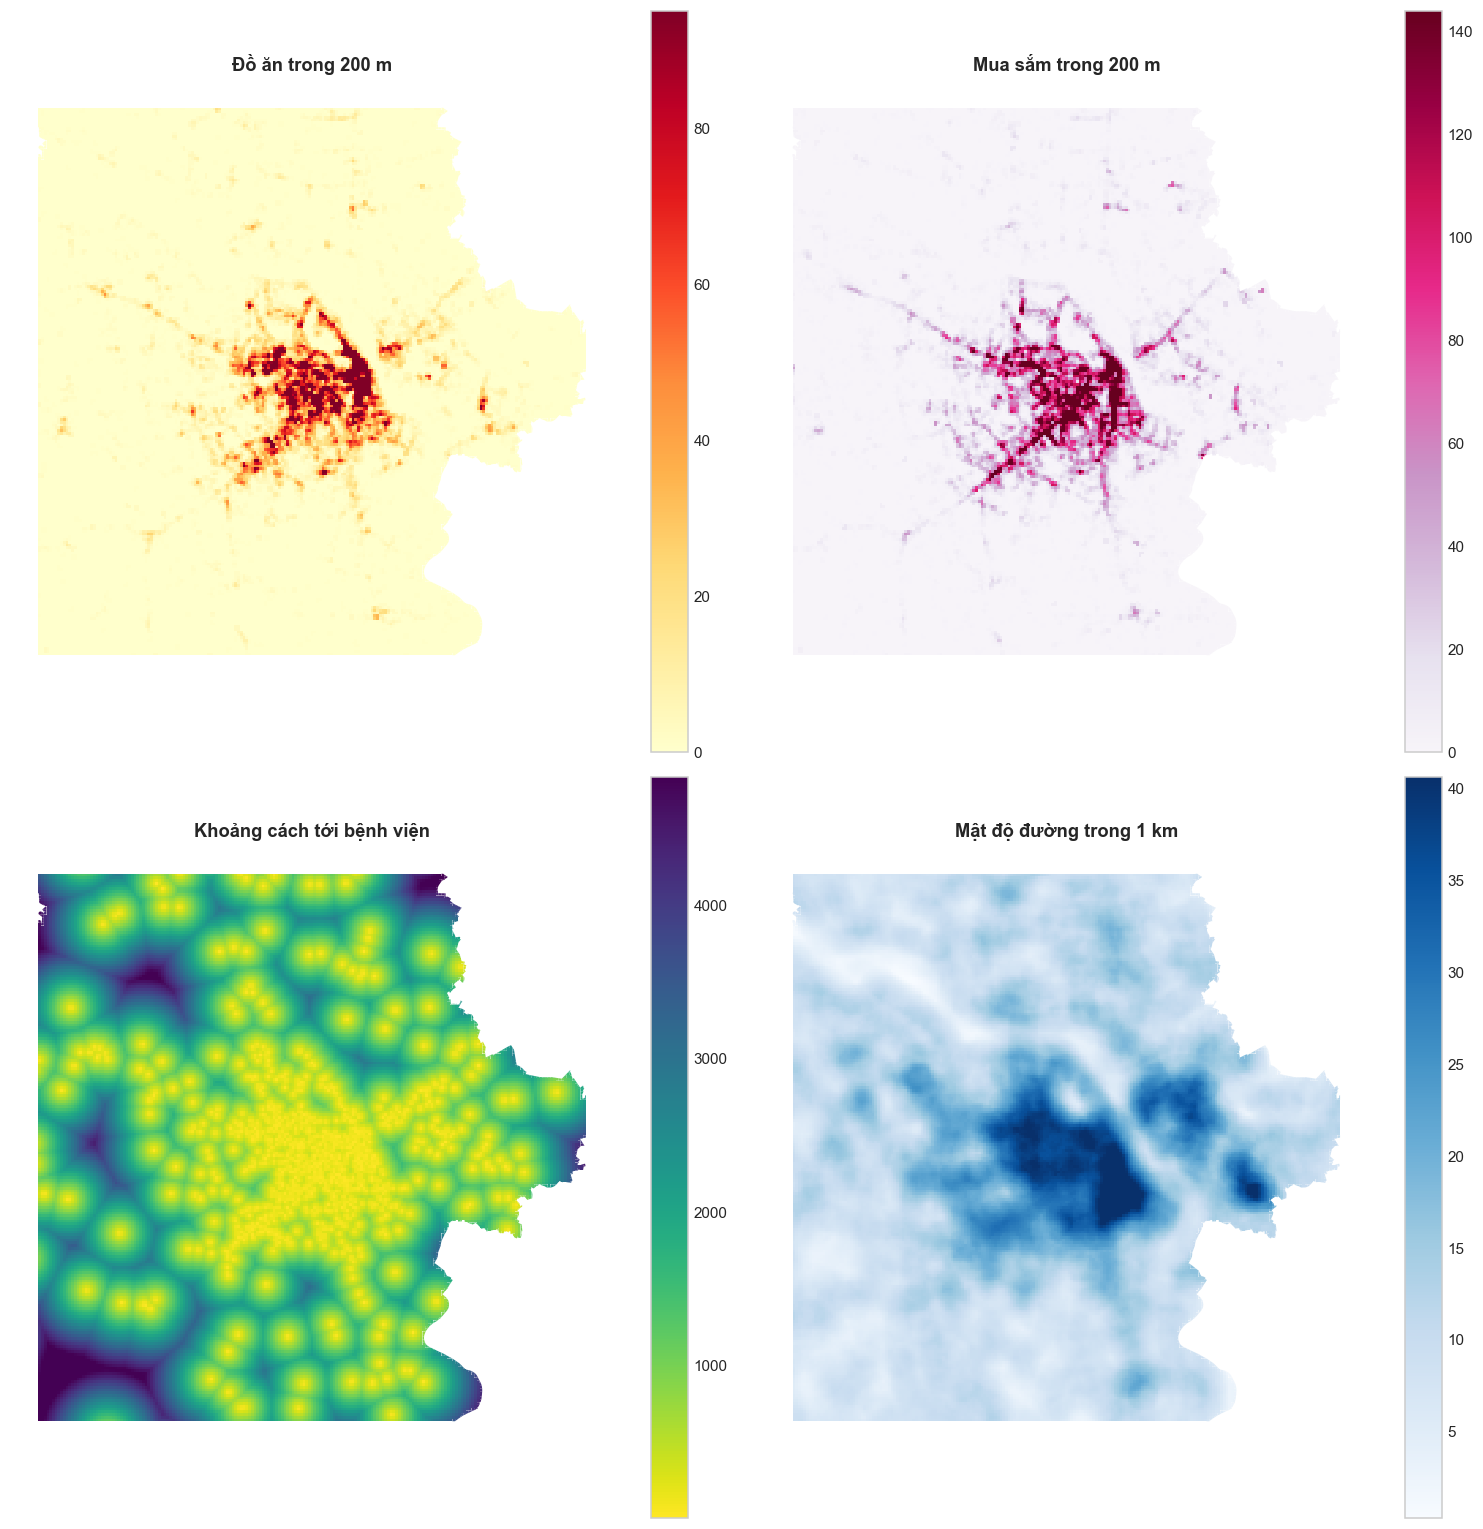

In [43]:
xmin, xmax, ymin, ymax = 565_000, 605_000, 2_305_000, 2_345_000
central = features.cx[xmin:xmax, ymin:ymax].copy()

map_specs = [
    ("food_and_drink_count_200m", "YlOrRd", "Đồ ăn trong 200 m", False),
    ("shopping_count_200m", "PuRd", "Mua sắm trong 200 m", False),
    ("nearest_hospital_m", "viridis_r", "Khoảng cách tới bệnh viện", True),
    ("road_density_1000m_km_per_km2", "Blues", "Mật độ đường trong 1 km", False),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for (column, cmap, title, is_distance), ax in zip(map_specs, axes.flat):
    plot_column = f"plot_{column}"
    central[plot_column] = central[column].clip(upper=central[column].quantile(0.99))
    central.plot(column=plot_column, cmap=cmap, legend=True, linewidth=0, ax=ax)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 8. Những cell có nhiều POI nhất

In [44]:
top_columns = [
    "cell_id",
    "poi_count",
    "food_and_drink_count_200m",
    "services_and_business_count_200m",
    "shopping_count_200m",
    "road_density_1000m_km_per_km2",
    "nearest_hospital_m",
]
top_cells = features.nlargest(10, "poi_count")[top_columns].copy()
display(top_cells.round(2))

,cell_id,poi_count,food_and_drink_count_200m,services_and_business_count_200m,shopping_count_200m,road_density_1000m_km_per_km2,nearest_hospital_m
63577,cell_063577,1744,166,460,559,39.63,34.43
63686,cell_063686,1158,357,344,482,34.33,31.78
63673,cell_063673,824,185,275,320,28.72,107.78
63609,cell_063609,622,182,175,343,37.66,21.55
63701,cell_063701,546,554,126,251,26.76,92.35
63699,cell_063699,544,569,127,327,29.02,50.24
63688,cell_063688,528,488,131,326,28.86,78.26
62631,cell_062631,495,57,347,357,30.56,89.20
62177,cell_062177,492,118,197,298,34.66,107.55
62248,cell_062248,471,180,212,376,39.64,37.23


## Kết luận mô tả dữ liệu

- Dataset có một hàng cho mỗi cell 200 m và giữ geometry để trực quan hóa không gian.
- POI được mô tả theo nhóm, nhiều bán kính và khoảng cách nearest.
- POI ở bán kính nhỏ có phân phối thưa và lệch phải: phần lớn cell có ít POI, một số cell trung tâm có rất nhiều.
- Khoảng cách nearest cho biết khả năng tiếp cận từng loại tiện ích.
- Road density mô tả mức độ kết nối và đô thị hóa quanh cell.
- Correlation và bản đồ cho thấy các khu vực trung tâm thường tập trung đồng thời nhiều POI và mạng đường dày hơn.

Các kết quả này chỉ mô tả dữ liệu. Notebook không chấm điểm, không đặt trọng số và không chạy suitability model.